In [ ]:
!unzip archive.zip

Archive:  archive.zip
  inflating: t10k-images-idx3-ubyte/t10k-images-idx3-ubyte  
  inflating: t10k-images.idx3-ubyte  
  inflating: t10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte  
  inflating: t10k-labels.idx1-ubyte  
  inflating: train-images-idx3-ubyte/train-images-idx3-ubyte  
  inflating: train-images.idx3-ubyte  
  inflating: train-labels-idx1-ubyte/train-labels-idx1-ubyte  
  inflating: train-labels.idx1-ubyte  


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time
import struct
np.random.seed(42)

In [ ]:
def read_idx_images(filepath):
    with open(filepath, 'rb') as f:
        magic, num_items, rows, cols = struct.unpack(">IIII", f.read(16))
        data = np.frombuffer(f.read(), dtype=np.uint8)
        X = data.reshape(num_items, rows * cols).astype(np.float32) / 255.0
        return X, (rows, cols)

def read_idx_labels(filepath):
    with open(filepath, 'rb') as f:
        magic, num_items = struct.unpack(">II", f.read(8))
        y = np.frombuffer(f.read(), dtype=np.uint8)
        return y

X_all, (H, W) = read_idx_images("train-images-idx3-ubyte/train-images-idx3-ubyte")
y_all = read_idx_labels("train-labels-idx1-ubyte/train-labels-idx1-ubyte")

X_test, _ = read_idx_images("t10k-images-idx3-ubyte/t10k-images-idx3-ubyte")
y_test = read_idx_labels("t10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte")

perm = np.random.permutation(len(X_all))
X_all_shuf = X_all[perm]
y_all_shuf = y_all[perm]

X_train, y_train = X_all_shuf[:50000], y_all_shuf[:50000]
X_val, y_val     = X_all_shuf[50000:], y_all_shuf[50000:]

In [ ]:
print(X_val.shape, y_val.shape, X_train.shape, y_train.shape)

(10000, 784) (10000,) (50000, 784) (50000,)


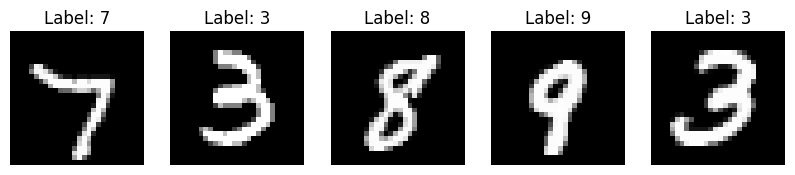

In [ ]:
n_show = 5
plt.figure(figsize=(10, 2))
for i in range(n_show):
    plt.subplot(1, n_show, i+1)
    plt.imshow(X_train[i].reshape(H, W), cmap="gray")
    plt.title(f"Label: {int(y_train[i])}")
    plt.axis("off")
plt.show()

In [ ]:
class ReLU():
    def forward(self, input):
        return np.maximum(0.0, input)

    def backward(self, input, grad_output):
        return grad_output * (input > 0)

class Dense():
    def __init__(self, input_units, output_units, learning_rate=0.1):
        self.learning_rate = learning_rate
        self.weights = (np.random.randn(input_units, output_units).astype(np.float32) *
                        np.sqrt(2.0 / input_units)).astype(np.float32)
        self.biases = np.zeros((output_units,), dtype=np.float32)

    def forward(self, input):
        return input @ self.weights + self.biases

    def backward(self, input, grad_output):
        grad_input = grad_output @ self.weights.T
        grad_weights = input.T @ grad_output
        grad_biases = grad_output.sum(axis=0)

        self.weights -= self.learning_rate * grad_weights
        self.biases  -= self.learning_rate * grad_biases
        return grad_input

In [ ]:
def softmax_crossentropy_with_logits(logits, reference_answers):
    """
    logits: (batch, classes)
    reference_answers: (batch,) int labels
    возвращает (batch,) loss
    """
    m = logits.shape[0]
    max_logits = np.max(logits, axis=1)  # (m,)
    shifted = logits - max_logits[:, None]
    logsumexp = np.log(np.sum(np.exp(shifted), axis=1)) + max_logits  # ВАЖНО: +max
    correct_logits = logits[np.arange(m), reference_answers]
    return -correct_logits + logsumexp

def grad_softmax_crossentropy_with_logits(logits, reference_answers):
    """
    dL/dlogits для mean loss по батчу
    """
    m = logits.shape[0]
    shifted = logits - np.max(logits, axis=1, keepdims=True)
    exp_shifted = np.exp(shifted)
    softmax = exp_shifted / np.sum(exp_shifted, axis=1, keepdims=True)

    onehot = np.zeros_like(logits)
    onehot[np.arange(m), reference_answers] = 1.0

    return (softmax - onehot) / m

In [ ]:
def forward(network, X):
    activations = []
    x = X
    for layer in network:
        x = layer.forward(x)
        activations.append(x)
    return activations

def predict(network, X):
    logits = forward(network, X)[-1]
    return np.argmax(logits, axis=-1)

def train_batch(network, X, y):
    layer_activations = forward(network, X)
    layer_inputs = [X] + layer_activations[:-1]
    logits = layer_activations[-1]

    loss = softmax_crossentropy_with_logits(logits, y)
    loss_grad = grad_softmax_crossentropy_with_logits(logits, y)

    grad = loss_grad
    for layer_idx in reversed(range(len(network))):
        layer = network[layer_idx]
        grad = layer.backward(layer_inputs[layer_idx], grad)

    return float(np.mean(loss))


In [ ]:
network = [
    Dense(784, 300, learning_rate=0.1),
    ReLU(),
    Dense(300, 10, learning_rate=0.1),
]

EPOCHS = 10
BATCH_SIZE = 64
num_samples = X_train.shape[0]

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    losses = []
    indices = np.random.permutation(num_samples)
    for start_idx in range(0, num_samples, BATCH_SIZE):
        batch_indices = indices[start_idx : start_idx + BATCH_SIZE]

        xb = X_train[batch_indices]
        yb = y_train[batch_indices]

        loss_val = train_batch(network, xb, yb)
        losses.append(loss_val)

    epoch_time = time.time() - t0

    train_correct = 0
    for s_idx in range(0, X_train.shape[0], 1024):
        e_idx = s_idx + 1024
        train_correct += np.sum(predict(network, X_train[s_idx:e_idx]) == y_train[s_idx:e_idx])
    train_err = 1.0 - (train_correct / X_train.shape[0])

    print(f"Эпоха {epoch} Время: {epoch_time:.2f} Loss: {np.mean(losses):.4f} Train error: {train_err:.4f}")


Эпоха 1 Время: 2.49 Loss: 0.3801 
 Train error: 0.0723
Эпоха 2 Время: 5.56 Loss: 0.2037 
 Train error: 0.0626
Эпоха 3 Время: 2.37 Loss: 0.1521 
 Train error: 0.0392
Эпоха 4 Время: 2.41 Loss: 0.1218 
 Train error: 0.0283
Эпоха 5 Время: 2.87 Loss: 0.1009 
 Train error: 0.0242
Эпоха 6 Время: 3.96 Loss: 0.0867 
 Train error: 0.0196
Эпоха 7 Время: 2.40 Loss: 0.0752 
 Train error: 0.0174
Эпоха 8 Время: 2.58 Loss: 0.0659 
 Train error: 0.0169
Эпоха 9 Время: 5.80 Loss: 0.0588 
 Train error: 0.0126
Эпоха 10 Время: 2.34 Loss: 0.0520 
 Train error: 0.0113


In [ ]:
test_correct = 0
for s_idx in range(0, X_test.shape[0], 1024):
    e_idx = s_idx + 1024
    test_correct += np.sum(predict(network, X_test[s_idx:e_idx]) == y_test[s_idx:e_idx])

test_acc = test_correct / X_test.shape[0]
test_err = 1.0 - test_acc


print(f"Error = {test_err:.4f} Accuracy = {test_acc*100:.2f}%")


Error = 0.0240 Accuracy = 97.60%
